Question 3.1 Compute the six measures in every frame and the five statistics for every video, obtaining a table of 
30 features with one row per video. Check that it has no missing values. The same functions compute 
the features of the test videos, which are set aside without being inspected.

In [8]:
import pandas as pd
import numpy as np
import math

og_df = pd.read_parquet("t1.1.gzip")
d = np.sqrt((og_df["x_45"] - og_df["x_36"])**2 + (og_df["y_45"] - og_df["y_36"])**2)
cols = {}

cols["video"] = og_df["video"]
cols["frame"] = og_df["frame"]
for k in range(68):
    cols[f"x_{k}"] = (og_df[f"x_{k}"] - og_df["x_27"]) / d
    cols[f"y_{k}"] = (og_df[f"y_{k}"] - og_df["y_27"]) / d

normalized_df = pd.DataFrame(cols)
normalized_df.to_parquet("normalized_data.gzip", compression="gzip")

def distance(df, a, b):
    return np.sqrt(
        (df[f"x_{a}"] - df[f"x_{b}"])**2
        + (df[f"y_{a}"] - df[f"y_{b}"])**2
    )

measurements = {}
measurements["video"] = normalized_df["video"]
measurements["frame"] = normalized_df["frame"]
#Mouth opening - δ(62, 66)
measurements["M1"]= distance(normalized_df, 66, 62)
#Mouth width - δ(48, 54)
measurements["M2"]= distance(normalized_df, 54, 48)
#Corner lift - mean y of 51 and 57 minus mean y of 48 and 54;positive when the corners of the mouth are above the centre of the lips
measurements["M3"]= ((normalized_df["y_51"] + normalized_df["y_57"]) / 2) - ((normalized_df["y_48"] + normalized_df["y_54"]) / 2)
#Brow height - mean y of 36–41 minus mean y of 17–21, averaged with mean y of 42–47 minus mean y of 22–26 (eye centroid minus brow centroid, both sides)
measurements["M4"]= (
    (
        (normalized_df["y_36"] + normalized_df["y_37"] + normalized_df["y_38"] + normalized_df["y_39"] + normalized_df["y_40"] + normalized_df["y_41"]) / 6
    ) - (
        (normalized_df["y_17"] + normalized_df["y_18"] + normalized_df["y_19"] + normalized_df["y_20"] + normalized_df["y_21"]) / 5
    ) + (
        (normalized_df["y_42"] + normalized_df["y_43"] + normalized_df["y_44"] + normalized_df["y_45"] + normalized_df["y_46"] + normalized_df["y_47"]) / 6
    ) - (
        (normalized_df["y_22"] + normalized_df["y_23"] + normalized_df["y_24"] + normalized_df["y_25"] + normalized_df["y_26"]) / 5
    )
) / 2
#Eye opening ¼ [δ(37, 41) + δ(38, 40) + δ(43, 47) + δ(44, 46)]
measurements["M5"]= (
    distance(normalized_df, 37, 41) +
    distance(normalized_df, 38, 40) +
    distance(normalized_df, 43, 47) +
    distance(normalized_df, 44, 46)
) / 4
#Brow gap δ(21, 22)
measurements["M6"]= distance(normalized_df, 21, 22)

per_frame_measurements_df = pd.DataFrame(measurements)
per_frame_measurements_df.to_parquet("per_frame_measurements.gzip", compression="gzip")

video_measurements = []
emotionLabels = ["Neutral", "Calm", "Happy", "Sad", "Angry", "Fearful", "Disgust", "Surprised"]

for video, group in per_frame_measurements_df.groupby("video"):
    emotion = int(video.split('-')[2])
    row = {
        "video": video,
        "emotion": emotionLabels[emotion-1]
    }
    group = group.sort_values("frame")
    for i in ["M1", "M2", "M3", "M4", "M5", "M6"]:
        row[f"{i}_mean"] = group[i].mean()
        row[f"{i}_std"] = group[i].std()
        row[f"{i}_range"] = group[i].max() - group[i].min()
        #mean absolute velocity, v - the mean of |m(t + 1) − m(t)| over the T − 1 pairs of consecutive frames
        row[f"{i}_v"] = (group[i].diff().abs().sum() / (len(group) - 1)) if len(group) > 1 else 0
        #movement energy, E - the mean of (m(t + 1) − m(t))² over the T − 1 pairs of consecutive frames
        row[f"{i}_E"] = (group[i].diff().pow(2).sum() / (len(group) - 1)) if len(group) > 1 else 0
    video_measurements.append(row)

video_measurements_df = pd.DataFrame(video_measurements)
print(video_measurements_df)
#check for missing values and print the number of missing values for each column
missing_values = video_measurements_df.isnull().sum()
#print(f"Missing values for each column:\n{missing_values}")

video_measurements_df.to_parquet("video_measurements.gzip", compression="gzip")


                         video    emotion   M1_mean    M1_std  M1_range  \
0     01-01-01-01-01-01-01.csv    Neutral  0.028165  0.022173  0.073449   
1     01-01-01-01-01-01-02.csv    Neutral  0.045541  0.042978  0.166364   
2     01-01-01-01-01-01-03.csv    Neutral  0.044769  0.030441  0.120792   
3     01-01-01-01-01-01-04.csv    Neutral  0.046652  0.045070  0.216453   
4     01-01-01-01-01-01-05.csv    Neutral  0.038562  0.022994  0.086473   
...                        ...        ...       ...       ...       ...   
1435  01-01-08-02-02-02-20.csv  Surprised  0.051768  0.032016  0.104523   
1436  01-01-08-02-02-02-21.csv  Surprised  0.148165  0.057368  0.269216   
1437  01-01-08-02-02-02-22.csv  Surprised  0.073067  0.034145  0.136747   
1438  01-01-08-02-02-02-23.csv  Surprised  0.033270  0.030631  0.111538   
1439  01-01-08-02-02-02-24.csv  Surprised  0.108972  0.061065  0.367009   

          M1_v      M1_E   M2_mean    M2_std  M2_range  ...   M5_mean  \
0     0.004131  0.000066  

In [10]:

testIndex = pd.read_parquet("testIndex.gzip")
print(video_measurements_df[~video_measurements_df["video"].isin(testIndex["video"])])

                         video   M1_mean    M1_std  M1_range      M1_v  \
1     01-01-01-01-01-01-02.csv  0.045541  0.042978  0.166364  0.007619   
2     01-01-01-01-01-01-03.csv  0.044769  0.030441  0.120792  0.006470   
3     01-01-01-01-01-01-04.csv  0.046652  0.045070  0.216453  0.007799   
4     01-01-01-01-01-01-05.csv  0.038562  0.022994  0.086473  0.004317   
5     01-01-01-01-01-01-06.csv  0.093865  0.059834  0.254196  0.010456   
...                        ...       ...       ...       ...       ...   
1434  01-01-08-02-02-02-19.csv  0.099246  0.029073  0.166773  0.008806   
1435  01-01-08-02-02-02-20.csv  0.051768  0.032016  0.104523  0.004976   
1436  01-01-08-02-02-02-21.csv  0.148165  0.057368  0.269216  0.015000   
1437  01-01-08-02-02-02-22.csv  0.073067  0.034145  0.136747  0.007584   
1438  01-01-08-02-02-02-23.csv  0.033270  0.030631  0.111538  0.006106   

          M1_E   M2_mean    M2_std  M2_range      M2_v  ...   M5_mean  \
1     0.000202  0.572101  0.016066  0.

Question 3.2 Propose and compute at least five features of your own, each with a sentence of justification stating 
the expression it targets and the landmarks it uses. Only information from the landmark files may be 
used: the fields of the file name other than the emotion (actor, intensity, statement, repetition) are 
not features.

In [13]:
import pandas as pd
import numpy as np

new_measurements_df = pd.read_parquet("per_frame_measurements.gzip")
normalized_df = pd.read_parquet("normalized_data.gzip")

#new features
#nose to lip distance - δ(33, 51)
new_measurements_df["M7"] = distance(normalized_df, 33, 51)
#nose width - δ(31, 35)
new_measurements_df["M8"] = distance(normalized_df, 31, 35)
#Inner-brow elevation relative to the outer brows 
new_measurements_df["M9"] = (normalized_df["y_19"] + normalized_df["y_24"]) / 2 - (normalized_df["y_21"] + normalized_df["y_22"]) / 2
#Lower-lip-to-chin distance
new_measurements_df["M10"] = distance(normalized_df, 57, 8)
#Vertical eye asymmetry
new_measurements_df["M11"] = (normalized_df["y_37"] + normalized_df["y_39"]) / 2 - (normalized_df["y_42"] + normalized_df["y_45"]) / 2

emotionLabels = ["Neutral", "Calm", "Happy", "Sad", "Angry", "Fearful", "Disgust", "Surprised"]
#statistical features for the new measurements
new_video_measurements = []
for video, group in new_measurements_df.groupby("video"):
    emotion = int(video.split('-')[2])
    row = {
        "video": video,
        "emotion": emotionLabels[emotion-1]
    }
    group = group.sort_values("frame")
    for i in ["M1", "M2", "M3", "M4", "M5", "M6", "M7", "M8", "M9", "M10", "M11"]:
        row[f"{i}_mean"] = group[i].mean()
        row[f"{i}_std"] = group[i].std()
        row[f"{i}_range"] = group[i].max() - group[i].min()
        #mean absolute velocity, v - the mean of |m(t + 1) − m(t)| over the T − 1 pairs of consecutive frames
        row[f"{i}_v"] = (group[i].diff().abs().sum() / (len(group) - 1)) if len(group) > 1 else 0
        #movement energy, E - the mean of (m(t + 1) − m(t))² over the T − 1 pairs of consecutive frames
        row[f"{i}_E"] = (group[i].diff().pow(2).sum() / (len(group) - 1)) if len(group) > 1 else 0
    new_video_measurements.append(row)

new_video_measurements_df = pd.DataFrame(new_video_measurements)

new_measurements_df.to_parquet("new_3.2_per_frame_measurements.gzip", compression="gzip")
new_video_measurements_df.to_parquet("new_3.2_video_measurements.gzip", compression="gzip")


Nose to lip feature: Disgust can involve raising the upper lip and wrinkling the nose. The distance between the nose base and upper lip may capture some of this movement, complementing the existing mouth-opening and corner-lift measures.

Nose width: Nose wrinkling or flaring can accompany disgust and may also occur in other expressions. Nose width adds information from a facial region not directly measured by the six existing features.

Inner-brow elevation relative to the outer brows: Sadness and fear can involve raising the inner eyebrows, while anger can involve a different brow configuration. This measure focuses on the shape of the eyebrows, rather than their average height relative to the eyes, which your existing M4 measures.

Lower-lip-to-chin distance: Lower-face tension and changes in lip position can accompany expressions such as anger, sadness, or disgust. This distance captures lower-face geometry not directly represented by the current measures, although its usefulness should be verified empirically.

Vertical eye asymmetry: When the head tilts sideways, the eyes can sit at different vertical positions in the image. This feature captures that asymmetry and may help the model account for pose differences that occur alongside emotional expressions.

In [14]:
print(new_measurements_df)
print(new_video_measurements_df)


                        video  frame        M1        M2        M3        M4  \
0    01-01-01-01-01-01-01.csv      1  0.005696  0.656869  0.042032  0.233281   
1    01-01-01-01-01-01-01.csv      2  0.008984  0.657265  0.042637  0.212851   
2    01-01-01-01-01-01-01.csv      3  0.010998  0.666838  0.043795  0.202312   
3    01-01-01-01-01-01-01.csv      4  0.011913  0.667316  0.042000  0.196198   
4    01-01-01-01-01-01-01.csv      5  0.012188  0.667504  0.041019  0.193234   
..                        ...    ...       ...       ...       ...       ...   
104  01-01-08-02-02-02-24.csv    105  0.096792  0.717591  0.127954  0.278653   
105  01-01-08-02-02-02-24.csv    106  0.097737  0.717628  0.129034  0.279310   
106  01-01-08-02-02-02-24.csv    107  0.098787  0.719736  0.130702  0.280016   
107  01-01-08-02-02-02-24.csv    108  0.097945  0.716695  0.129830  0.279633   
108  01-01-08-02-02-02-24.csv    109  0.099284  0.716460  0.132926  0.277468   

           M5        M6        M7      

Question 3.3 For at least four features, plot the distribution per emotion. Which emotions does each feature 
separate, and which does it confuse?

['video', 'emotion', 'M1_mean', 'M1_std', 'M1_range', 'M1_v', 'M1_E', 'M2_mean', 'M2_std', 'M2_range', 'M2_v', 'M2_E', 'M3_mean', 'M3_std', 'M3_range', 'M3_v', 'M3_E', 'M4_mean', 'M4_std', 'M4_range', 'M4_v', 'M4_E', 'M5_mean', 'M5_std', 'M5_range', 'M5_v', 'M5_E', 'M6_mean', 'M6_std', 'M6_range', 'M6_v', 'M6_E', 'M7_mean', 'M7_std', 'M7_range', 'M7_v', 'M7_E', 'M8_mean', 'M8_std', 'M8_range', 'M8_v', 'M8_E', 'M9_mean', 'M9_std', 'M9_range', 'M9_v', 'M9_E', 'M10_mean', 'M10_std', 'M10_range', 'M10_v', 'M10_E', 'M11_mean', 'M11_std', 'M11_range', 'M11_v', 'M11_E']


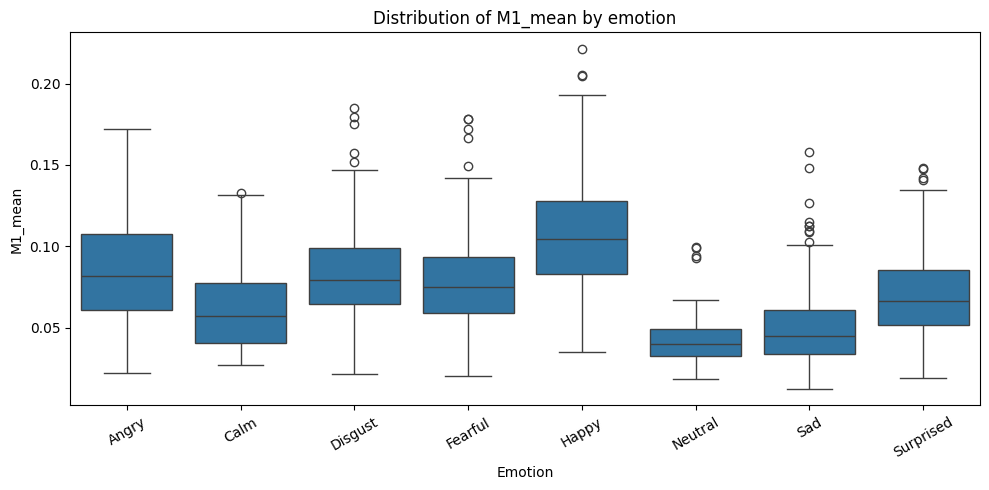

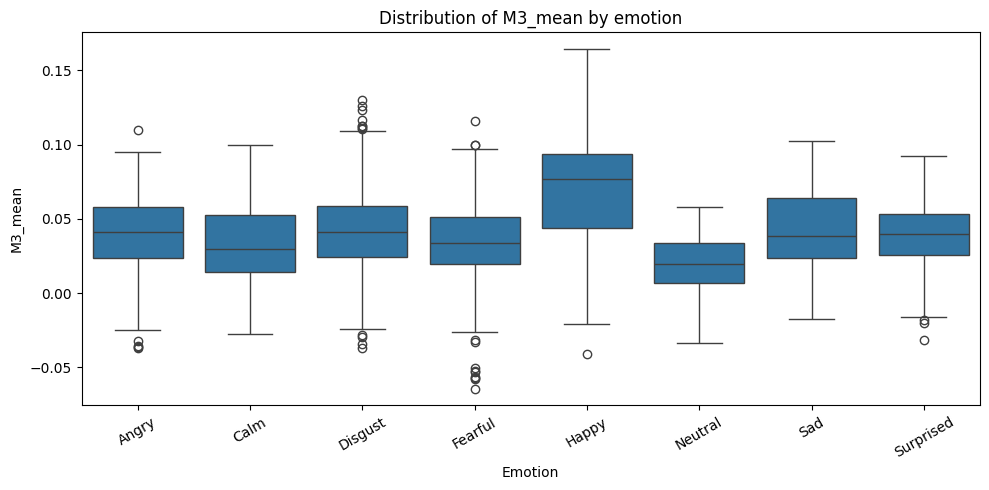

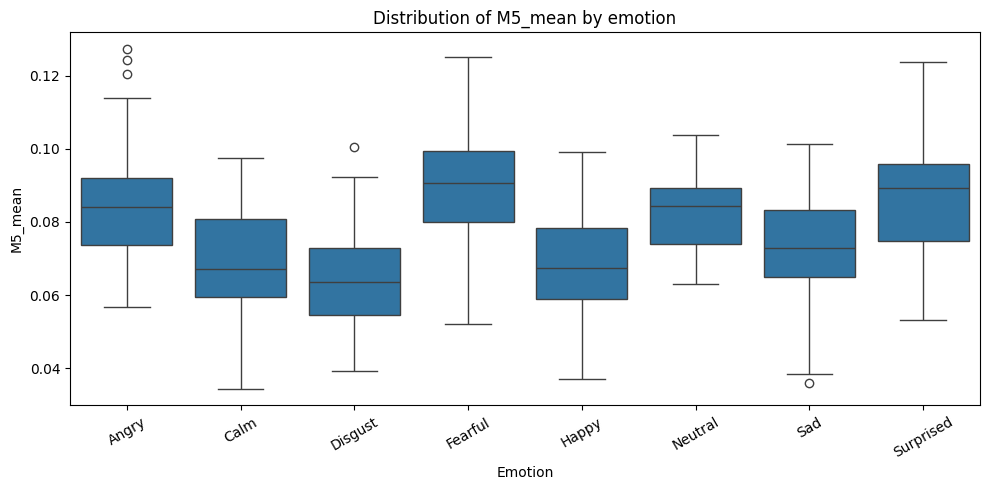

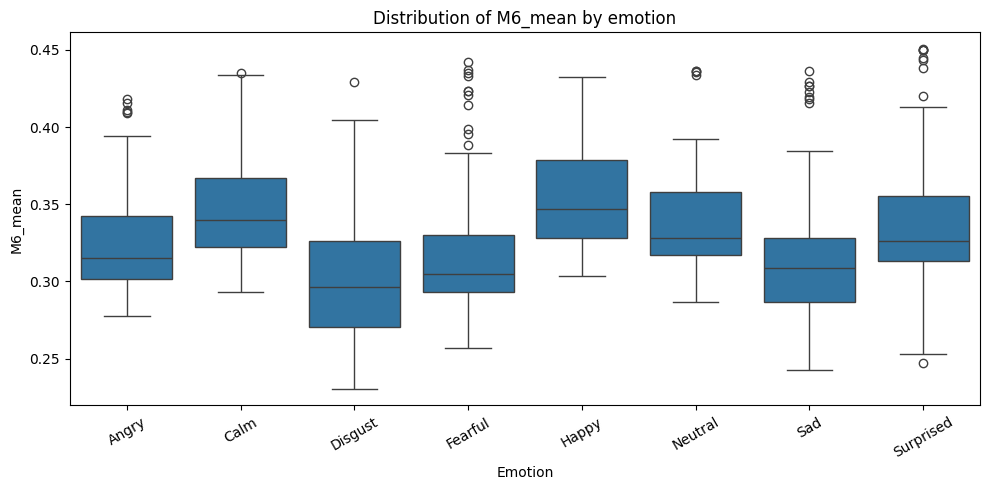

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

videos = pd.read_parquet("new_3.2_video_measurements.gzip")
print(videos.columns.tolist())
grouped = videos.groupby("emotion")

features_to_plot = [
    "M1_mean",  # Mean mouth opening
    "M3_mean",  # Mean mouth-corner lift
    "M5_mean",  # Mean eye opening
    "M6_mean",  # Mean brow gap
]

# Ensure emotions appear in a consistent order
emotion_order = sorted(videos["emotion"].dropna().unique())

# Create one plot per feature
for feature in features_to_plot:
    plt.figure(figsize=(10, 5))

    sns.boxplot(
        data=videos,
        x="emotion",
        y=feature,
        order=emotion_order
    )

    plt.title(f"Distribution of {feature} by emotion")
    plt.xlabel("Emotion")
    plt.ylabel(feature)
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

M1_mean - Mean mouth opening
M3_mean - Mean mouth-corner lift
M5_mean - Mean eye opening
M6_mean - Mean brow gap

In M1_mean we can see that Happy can be seperated from the other emotions by how much higher its median, and that Neutral, similarly, can also be seperated by how much lower its median is.
For M3_mean, we continue to see the pattern of Happy having the highest median while Neutral has the lowest, though this time, Neutral's low median isn't as obvious.
For M5_mean, Fearful and Surprise stand out by having higher medians, which makes sense since M5 represents the openess of the eye and Fearful and Surprised is when people open their eyes wide to capture has much information as they can.
For M6_mean, Happy stands out again with it's higher median but, this time, it's Disgust, not Neutral, that has the lowest median. 

Question 3.4 Compute the correlation matrix of all the features, those of Tables 2 and 3 and those of 3.2, and 
identify the groups of strongly correlated features, for example with |r| > 0.9. What do these groups 
imply for a method that selects features one at a time by their individual relevance?

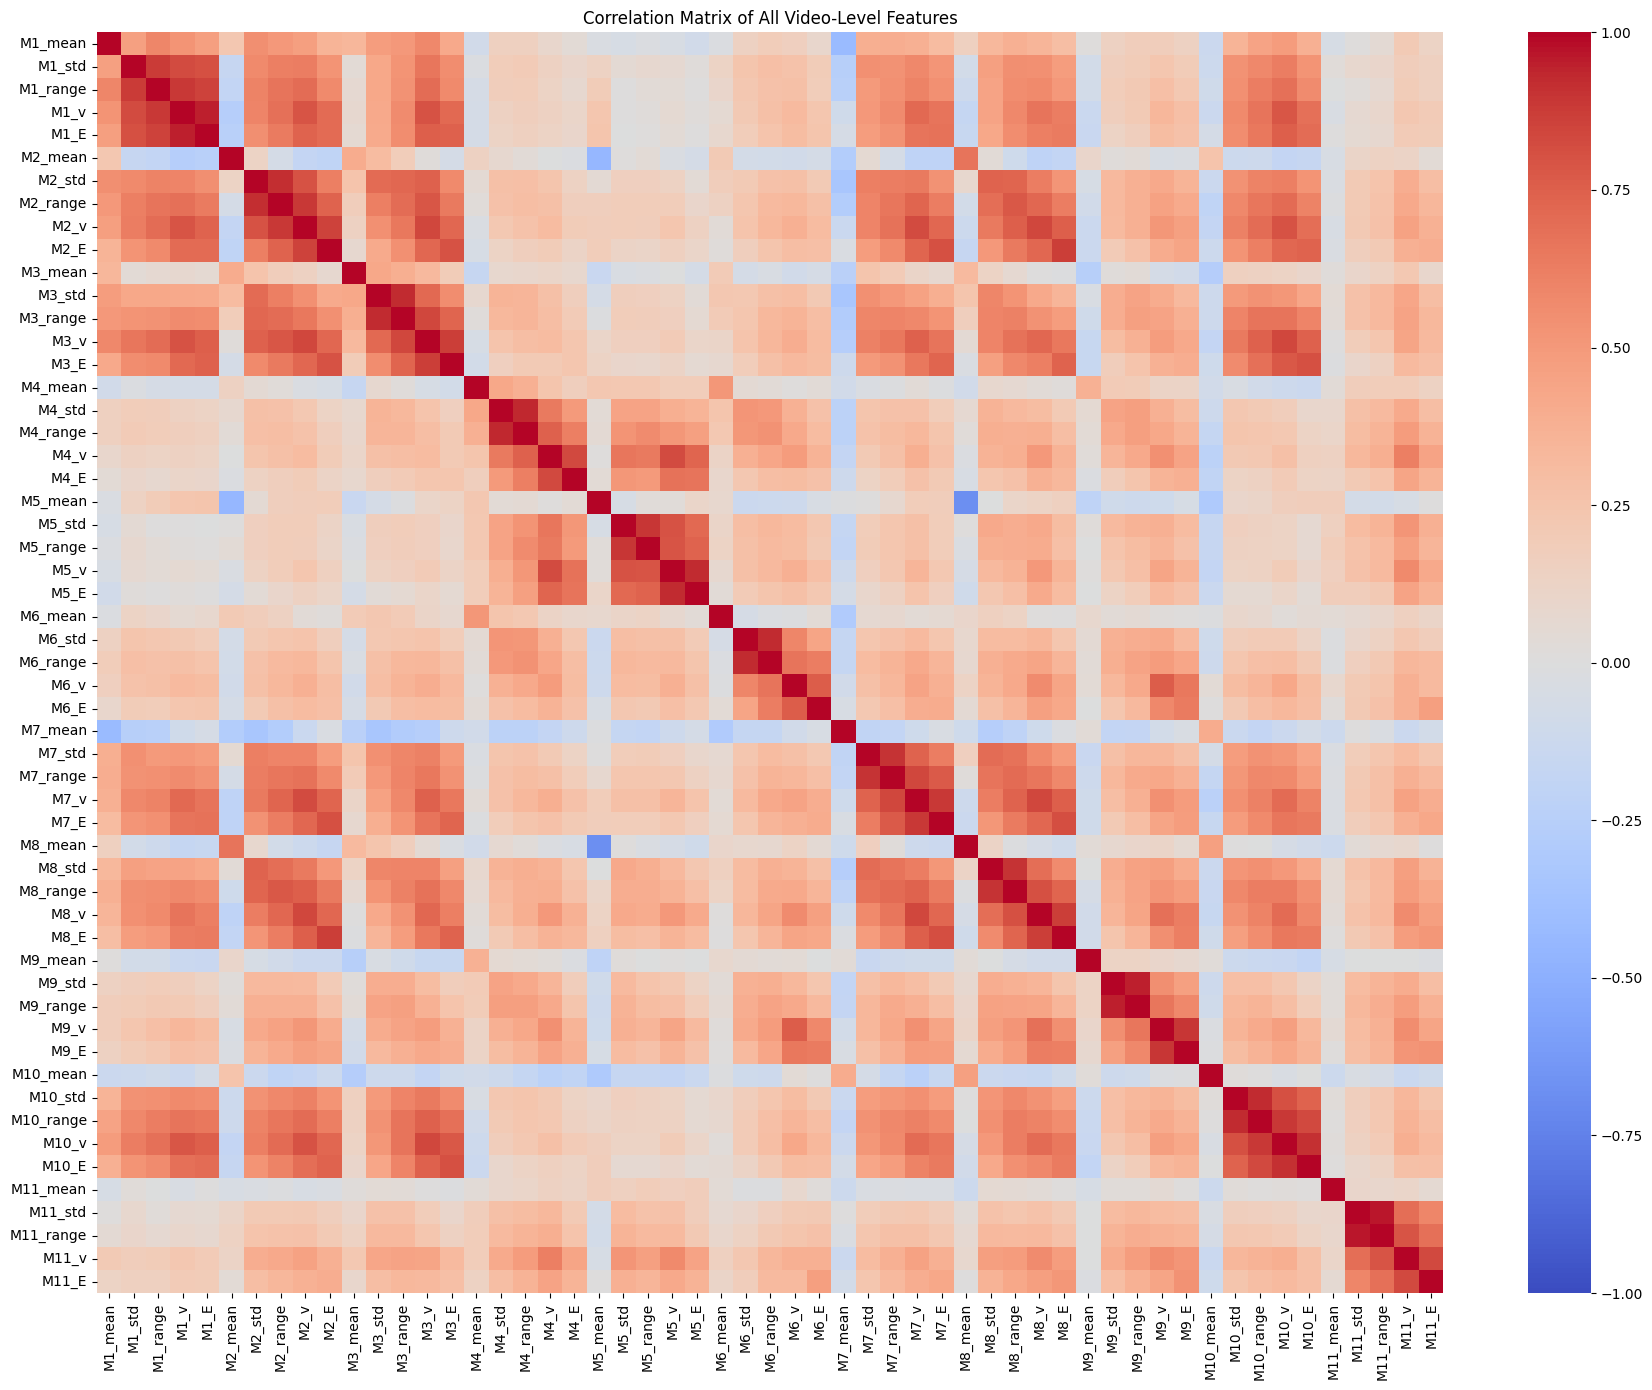

M11_std  M11_range    0.963410
M9_std   M9_range     0.952884
M1_v     M1_E         0.949372
M4_std   M4_range     0.931239
M10_std  M10_range    0.927814
M6_std   M6_range     0.924540
M5_v     M5_E         0.922149
M3_std   M3_range     0.922108
M2_std   M2_range     0.920479
M10_v    M10_E        0.906973
M7_std   M7_range     0.905908
M8_std   M8_range     0.901953
dtype: float64


In [4]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

video_measurements_df = pd.read_parquet("new_3.2_video_measurements.gzip")

feature_cols = [
    c for c in video_measurements_df.select_dtypes(include="number").columns
]
corr_matrix = video_measurements_df[feature_cols].corr()


plt.figure(figsize=(18, 14))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)
plt.title("Correlation Matrix of All Video-Level Features")
plt.tight_layout()
plt.show()

# Find strongly correlated feature pairs
strong_pairs = (
    corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )
    .stack()
    .loc[lambda s: s.abs() > 0.9]
    .sort_values(key=abs, ascending=False)
)

print(strong_pairs)